# XAUUSD H1 — Per-Strategy Position Capacity Experiment

## Objective

Implement the selected H1 trading rules with an explicit position-capacity policy:

1. **Maximum one open Bullish N position at a time.**
2. **Maximum one open Ranging N position at a time.**
3. **Bullish N and Ranging N positions may be open simultaneously.** The combined strategy stream can therefore hold up to two positions.
4. Apply the selected EMA/ADX regime mapping at setup confirmation:
   - Bullish N is eligible only in a **Bullish** regime.
   - Ranging N is eligible only in a **Sideways** regime.
   - Bearish N is not traded.

This notebook uses the existing **3-bar pivot definition** (three candles on each side) as the reference configuration from Notebook 01 / Notebook 04. It does not optimize swing width.

### Important implementation detail

Notebook 04 generated all signals, backtested each strategy independently with one position at a time, and filtered the completed trade records by regime afterward. That already allowed Bullish N and Ranging N trades to overlap. However, an ineligible trade could occupy that strategy's position slot and prevent a later eligible signal from being taken.

This notebook applies the regime eligibility rule **before** each strategy's backtest. Thus, only eligible signals compete for that strategy's single position slot. It then audits concurrency to verify that each strategy has at most one open position and that Bullish and Ranging positions can overlap.

The results below are full-sample historical exploratory backtest results, not a validated trading system.

In [1]:
from __future__ import annotations

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from numpy.lib.stride_tricks import sliding_window_view

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "XAUUSD_H1.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
ASSET_DIR = PROJECT_ROOT / "assets"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ASSET_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Run this notebook from the project root or notebooks/ folder."
    )

# Fixed reference parameters: same as the 3-bar H1 baseline.
SWING_BARS_EACH_SIDE = 3
ATR_PERIOD = 14
RR = 2.0
ENTRY_BUFFER_ATR = 0.05
SL_BUFFER_ATR = 0.05
RANGE_TOLERANCE_ATR = 0.50
PENDING_EXPIRY_BARS = 20
EMA_FAST = 50
EMA_SLOW = 200
ADX_PERIOD = 14
ADX_THRESHOLD = 20.0

print("Project root:", PROJECT_ROOT)
print("Data path:", DATA_PATH)
print("Position rules: max 1 Bullish N + max 1 Ranging N; cross-strategy overlap allowed.")

Project root: /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern
Data path: /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/data/XAUUSD_H1.csv
Position rules: max 1 Bullish N + max 1 Ranging N; cross-strategy overlap allowed.


## 1. Load H1 candles and calculate the EMA/ADX baseline regime

Regime is determined on the completed setup-confirmation candle. Pending stop orders become active on the following H1 candle.

In [2]:
raw = pd.read_csv(DATA_PATH, header=None)
if raw.shape[1] < 5:
    raise ValueError("The H1 source CSV must contain Date, Open, High, Low, and Close columns.")

column_names = ["Date", "Open", "High", "Low", "Close"]
if raw.shape[1] >= 6:
    column_names.append("Volume")
raw = raw.iloc[:, :len(column_names)].copy()
raw.columns = column_names
raw["Date"] = pd.to_datetime(raw["Date"], errors="coerce")
for col in ["Open", "High", "Low", "Close"]:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")
if "Volume" in raw.columns:
    raw["Volume"] = pd.to_numeric(raw["Volume"], errors="coerce")

data = (
    raw.dropna(subset=["Date", "Open", "High", "Low", "Close"])
       .sort_values("Date")
       .drop_duplicates("Date")
       .set_index("Date")
)

invalid = (data["High"] < data[["Open", "Close", "Low"]].max(axis=1)) | (
    data["Low"] > data[["Open", "Close", "High"]].min(axis=1)
)
if invalid.any():
    raise ValueError(f"Found {int(invalid.sum())} invalid OHLC rows.")

prev_close = data["Close"].shift(1)
true_range = pd.concat([
    data["High"] - data["Low"],
    (data["High"] - prev_close).abs(),
    (data["Low"] - prev_close).abs(),
], axis=1).max(axis=1)
data["ATR"] = true_range.rolling(ATR_PERIOD, min_periods=ATR_PERIOD).mean()

data["EMA50"] = data["Close"].ewm(span=EMA_FAST, adjust=False, min_periods=EMA_FAST).mean()
data["EMA200"] = data["Close"].ewm(span=EMA_SLOW, adjust=False, min_periods=EMA_SLOW).mean()
up_move = data["High"].diff()
down_move = -data["Low"].diff()
plus_dm = pd.Series(np.where((up_move > down_move) & (up_move > 0), up_move, 0.0), index=data.index)
minus_dm = pd.Series(np.where((down_move > up_move) & (down_move > 0), down_move, 0.0), index=data.index)
smoothed_tr = true_range.ewm(alpha=1 / ADX_PERIOD, adjust=False, min_periods=ADX_PERIOD).mean()
smoothed_plus_dm = plus_dm.ewm(alpha=1 / ADX_PERIOD, adjust=False, min_periods=ADX_PERIOD).mean()
smoothed_minus_dm = minus_dm.ewm(alpha=1 / ADX_PERIOD, adjust=False, min_periods=ADX_PERIOD).mean()
data["+DI14"] = 100 * smoothed_plus_dm / smoothed_tr
data["-DI14"] = 100 * smoothed_minus_dm / smoothed_tr
dx = 100 * (data["+DI14"] - data["-DI14"]).abs() / (data["+DI14"] + data["-DI14"])
data["ADX14"] = dx.ewm(alpha=1 / ADX_PERIOD, adjust=False, min_periods=ADX_PERIOD).mean()

conditions = [
    data["ADX14"] < ADX_THRESHOLD,
    (data["ADX14"] >= ADX_THRESHOLD) & (data["EMA50"] > data["EMA200"]),
    (data["ADX14"] >= ADX_THRESHOLD) & (data["EMA50"] < data["EMA200"]),
]
data["Regime"] = np.select(conditions, ["Sideways", "Bullish", "Bearish"], default="Unclassified")

print(f"Rows: {len(data):,}")
print(f"Period: {data.index.min()} to {data.index.max()}")
display(data[["Open", "High", "Low", "Close", "ATR", "EMA50", "EMA200", "ADX14", "Regime"]].tail())
display(data["Regime"].value_counts().rename_axis("Regime").to_frame("Bars"))

Rows: 100,000
Period: 2010-02-22 18:00:00 to 2026-11-12 06:00:00


,Open,High,Low,Close,ATR,EMA50,EMA200,ADX14,Regime
Date,,,,,,,,,
2026-11-12 02:00:00,3985.415,3989.760,3973.685,3980.377,14.192857,4036.380630,4046.640681,36.092844,Bearish
2026-11-12 03:00:00,3980.375,3984.860,3976.535,3982.608,14.298929,4034.271899,4046.003539,36.622316,Bearish
2026-11-12 04:00:00,3982.608,3983.317,3972.595,3975.208,14.018357,4031.955668,4045.299106,37.332925,Bearish
2026-11-12 05:00:00,3975.208,3982.911,3969.525,3979.407,13.008429,4029.894936,4044.643463,38.158972,Bearish
2026-11-12 06:00:00,3979.407,3980.750,3962.245,3965.600,13.050429,4027.373566,4043.856961,39.291329,Bearish


,Bars
Regime,
Bullish,37711
Bearish,31640
Sideways,30461
Unclassified,188


## 2. Confirm 3-bar swing pivots without look-ahead

A pivot candidate is the center candle of a 7-candle window (3 candles on each side). The pivot is only available at its confirmation candle, three H1 bars after the pivot candle. The tie-handling rule matches the existing notebooks: the center must be the extreme, and an equal extreme to its right disqualifies it.

In [3]:
def confirmed_pivots(frame: pd.DataFrame, left: int = SWING_BARS_EACH_SIDE,
                     right: int = SWING_BARS_EACH_SIDE) -> list[dict]:
    highs = frame["High"].to_numpy(dtype=float)
    lows = frame["Low"].to_numpy(dtype=float)
    width = left + right + 1
    if len(frame) < width:
        return []

    high_windows = sliding_window_view(highs, width)
    low_windows = sliding_window_view(lows, width)
    center_high = high_windows[:, left]
    center_low = low_windows[:, left]
    is_high = (center_high >= high_windows.max(axis=1)) & ~(
        high_windows[:, left + 1:] == center_high[:, None]
    ).any(axis=1)
    is_low = (center_low <= low_windows.min(axis=1)) & ~(
        low_windows[:, left + 1:] == center_low[:, None]
    ).any(axis=1)

    points = []
    for offset in np.flatnonzero(is_high | is_low):
        pivot_i = int(offset + left)
        confirm_i = pivot_i + right
        if is_high[offset]:
            points.append({"type": "H", "pivot_i": pivot_i, "confirm_i": confirm_i,
                           "price": float(highs[pivot_i]), "date": frame.index[pivot_i]})
        if is_low[offset]:
            points.append({"type": "L", "pivot_i": pivot_i, "confirm_i": confirm_i,
                           "price": float(lows[pivot_i]), "date": frame.index[pivot_i]})
    points.sort(key=lambda p: (p["confirm_i"], p["pivot_i"]))
    return points

pivots = confirmed_pivots(data)
print(f"Confirmed swing pivots: {len(pivots):,}")

Confirmed swing pivots: 19,846


## 3. Generate Bullish N and Ranging N candidates

The pattern definitions are unchanged from Notebook 04:

- **Bullish N:** Low → High → Higher Low. Buy stop above P2; stop below P3.
- **Ranging N:** Four alternating pivots (`H-L-H-L` or `L-H-L-H`) with the two highs and two lows each within 0.50 ATR. Place OCO breakout orders beyond the range boundaries.

Bearish N is excluded because the selected H1 trading plan does not take Bearish N signals.

In [4]:
def build_selected_setups(frame: pd.DataFrame, pivot_points: list[dict]) -> dict[str, list[dict]]:
    atr = frame["ATR"].to_numpy(dtype=float)
    candidates = {"bullish": [], "ranging": []}

    # Bullish N: Low -> High -> Higher Low.
    for k in range(2, len(pivot_points)):
        p1, p2, p3 = pivot_points[k - 2:k + 1]
        if [p1["type"], p2["type"], p3["type"]] != ["L", "H", "L"]:
            continue
        if not (p3["price"] > p1["price"] and p2["price"] > p1["price"]):
            continue
        signal_i = int(p3["confirm_i"])
        a = atr[signal_i]
        if not np.isfinite(a) or a <= 0:
            continue
        entry = p2["price"] + ENTRY_BUFFER_ATR * a
        sl = p3["price"] - SL_BUFFER_ATR * a
        if sl < entry:
            candidates["bullish"].append({
                "signal_i": signal_i,
                "setup_type": "bullish",
                "orders": [{"side": "long", "entry": entry, "sl": sl}],
                "pattern": f"P1={p1['price']:.2f}; P2={p2['price']:.2f}; P3={p3['price']:.2f}",
            })

    # Ranging N: two similar highs and two similar lows over four alternating pivots.
    for k in range(3, len(pivot_points)):
        q = pivot_points[k - 3:k + 1]
        types = [point["type"] for point in q]
        if types not in (["H", "L", "H", "L"], ["L", "H", "L", "H"]):
            continue
        highs = [point["price"] for point in q if point["type"] == "H"]
        lows = [point["price"] for point in q if point["type"] == "L"]
        signal_i = int(q[-1]["confirm_i"])
        a = atr[signal_i]
        if not np.isfinite(a) or a <= 0:
            continue
        range_high, range_low = max(highs), min(lows)
        high_ok = abs(highs[1] - highs[0]) <= RANGE_TOLERANCE_ATR * a
        low_ok = abs(lows[1] - lows[0]) <= RANGE_TOLERANCE_ATR * a
        if high_ok and low_ok and range_high > range_low:
            candidates["ranging"].append({
                "signal_i": signal_i,
                "setup_type": "ranging",
                "orders": [
                    {"side": "long", "entry": range_high + ENTRY_BUFFER_ATR * a,
                     "sl": range_low - SL_BUFFER_ATR * a},
                    {"side": "short", "entry": range_low - ENTRY_BUFFER_ATR * a,
                     "sl": range_high + SL_BUFFER_ATR * a},
                ],
                "pattern": f"RangeLow={range_low:.2f}; RangeHigh={range_high:.2f}",
            })
    return candidates

candidate_setups = build_selected_setups(data, pivots)
print("Candidate setup counts:", {k: len(v) for k, v in candidate_setups.items()})

Candidate setup counts: {'bullish': 3135, 'ranging': 622}


## 4. Apply regime eligibility before position allocation

This is the key difference from the previous Notebook 04 reporting sequence. Only eligible setups are passed to the backtest:

- Bullish N candidates are retained only when the signal-confirmation candle is Bullish.
- Ranging N candidates are retained only when the signal-confirmation candle is Sideways.

An ineligible setup therefore cannot consume that strategy's one-position slot.

In [5]:
regime_values = data["Regime"].to_numpy()
eligible_setups = {
    "bullish": [s for s in candidate_setups["bullish"]
                if regime_values[int(s["signal_i"])] == "Bullish"],
    "ranging": [s for s in candidate_setups["ranging"]
                if regime_values[int(s["signal_i"])] == "Sideways"],
}

eligibility_summary = pd.DataFrame([
    {"Strategy": "Bullish N", "Required regime": "Bullish",
     "All candidates": len(candidate_setups["bullish"]),
     "Eligible candidates": len(eligible_setups["bullish"])},
    {"Strategy": "Ranging N", "Required regime": "Sideways",
     "All candidates": len(candidate_setups["ranging"]),
     "Eligible candidates": len(eligible_setups["ranging"])},
])
display(eligibility_summary)

,Strategy,Required regime,All candidates,Eligible candidates
0,Bullish N,Bullish,3135,1135
1,Ranging N,Sideways,622,277


## 5. Backtest with one position slot per strategy

Each strategy has its **own independent position lock** (`busy_until`). A Bullish N position does not block a Ranging N signal, and vice versa. Within each strategy, once an order is filled, later signals are skipped until that position exits.

Execution assumptions are held fixed: orders activate on the next candle, expire after 20 H1 bars, entries are gap-aware, same-candle SL/TP touches assume SL first, and OCO orders triggered on the same bar are marked ambiguous.

In [6]:
def backtest_one_strategy(frame: pd.DataFrame, setup_list: list[dict]) -> pd.DataFrame:
    n = len(frame)
    idx = frame.index
    open_ = frame["Open"].to_numpy(dtype=float)
    high = frame["High"].to_numpy(dtype=float)
    low = frame["Low"].to_numpy(dtype=float)
    close = frame["Close"].to_numpy(dtype=float)
    regime_arr = frame["Regime"].to_numpy()
    results = []
    busy_until = -1  # A separate lock is created by calling this function per strategy.

    for setup in sorted(setup_list, key=lambda item: item["signal_i"]):
        signal_i = int(setup["signal_i"])
        if signal_i + 1 >= n:
            continue
        if signal_i <= busy_until:
            continue

        first_active = signal_i + 1
        last_active = min(n - 1, first_active + PENDING_EXPIRY_BARS - 1)
        valid_order_hits = []

        for order in setup["orders"]:
            side = order["side"]
            entry_level = float(order["entry"])
            stop_level = float(order["sl"])
            touched = (high[first_active:last_active + 1] >= entry_level) if side == "long" else (
                low[first_active:last_active + 1] <= entry_level
            )
            for offset in np.flatnonzero(touched):
                entry_i = first_active + int(offset)
                fill = max(entry_level, float(open_[entry_i])) if side == "long" else min(
                    entry_level, float(open_[entry_i])
                )
                if (side == "long" and stop_level >= fill) or (side == "short" and stop_level <= fill):
                    continue
                risk = abs(fill - stop_level)
                target = fill + RR * risk if side == "long" else fill - RR * risk
                valid_order_hits.append({"i": entry_i, "side": side, "entry": fill,
                                         "sl": stop_level, "tp": target, "risk": risk})
                break

        if not valid_order_hits:
            continue

        earliest_i = min(hit["i"] for hit in valid_order_hits)
        hits_at_earliest = [hit for hit in valid_order_hits if hit["i"] == earliest_i]
        if len(hits_at_earliest) > 1:
            results.append({
                "setup": setup["setup_type"], "side": "ambiguous",
                "signal_date": idx[signal_i], "entry_date": idx[earliest_i],
                "entry": np.nan, "sl": np.nan, "tp": np.nan,
                "exit_date": idx[earliest_i], "exit": np.nan,
                "result": "AMBIGUOUS_BOTH_SIDES", "R": 0.0, "bars_held": 0,
                "pattern": setup.get("pattern", ""), "signal_regime": regime_arr[signal_i],
            })
            busy_until = earliest_i
            continue

        hit = hits_at_earliest[0]
        side, entry, stop_level, target, risk = (
            hit["side"], hit["entry"], hit["sl"], hit["tp"], hit["risk"]
        )
        start = earliest_i
        stop_hits = (low[start:] <= stop_level) if side == "long" else (high[start:] >= stop_level)
        target_hits = (high[start:] >= target) if side == "long" else (low[start:] <= target)
        exit_offsets = np.flatnonzero(stop_hits | target_hits)

        if len(exit_offsets):
            offset = int(exit_offsets[0])
            exit_i = start + offset
            if stop_hits[offset]:  # Conservative rule: SL takes precedence on same candle.
                if side == "long":
                    exit_price = min(stop_level, float(open_[exit_i])) if open_[exit_i] < stop_level else stop_level
                else:
                    exit_price = max(stop_level, float(open_[exit_i])) if open_[exit_i] > stop_level else stop_level
                result = "SL"
            else:
                if side == "long":
                    exit_price = max(target, float(open_[exit_i])) if open_[exit_i] > target else target
                else:
                    exit_price = min(target, float(open_[exit_i])) if open_[exit_i] < target else target
                result = "TP"
        else:
            exit_i = n - 1
            exit_price = float(close[-1])
            result = "OPEN_AT_END"

        pnl_points = exit_price - entry if side == "long" else entry - exit_price
        r_multiple = pnl_points / risk if risk > 0 else np.nan
        results.append({
            "setup": setup["setup_type"], "side": side,
            "signal_date": idx[signal_i], "entry_date": idx[start],
            "entry": entry, "sl": stop_level, "tp": target,
            "exit_date": idx[exit_i], "exit": exit_price,
            "result": result, "R": r_multiple, "bars_held": exit_i - start + 1,
            "pattern": setup.get("pattern", ""), "signal_regime": regime_arr[signal_i],
        })
        busy_until = exit_i

    return pd.DataFrame(results)

# Each call gets a separate `busy_until` lock: one Bullish slot and one Ranging slot.
strategy_trades = {
    strategy: backtest_one_strategy(data, setup_list)
    for strategy, setup_list in eligible_setups.items()
}

all_trades = pd.concat(strategy_trades.values(), ignore_index=True)
if not all_trades.empty:
    all_trades = all_trades.sort_values(["entry_date", "setup", "signal_date"]).reset_index(drop=True)

print("Trade records by strategy (ambiguous OCO records are shown separately):")
for strategy, frame in strategy_trades.items():
    print(f"{strategy}: {len(frame):,} trade records")

Trade records by strategy (ambiguous OCO records are shown separately):
bullish: 566 trade records
ranging: 197 trade records


## 6. Performance statistics

`Net R` is the sum of trade outcomes in units of initial risk. The combined result adds the independently generated Bullish and Ranging trade streams; it is not a cash-equity simulation with dynamic lot sizing or margin.

In [7]:
VALID_RESULTS = ["TP", "SL", "OPEN_AT_END"]

def summarize_performance(frame: pd.DataFrame) -> dict:
    valid = frame[frame["result"].isin(VALID_RESULTS)].copy()
    ambiguous = int((frame["result"] == "AMBIGUOUS_BOTH_SIDES").sum()) if len(frame) else 0
    if valid.empty:
        return {"Trades": 0, "Win rate %": np.nan, "Net R": 0.0,
                "Profit factor": np.nan, "Avg R": np.nan,
                "Max drawdown R": 0.0, "Ambiguous OCO": ambiguous}

    valid = valid.sort_values(["exit_date", "signal_date"])
    gross_profit = valid.loc[valid["R"] > 0, "R"].sum()
    gross_loss = -valid.loc[valid["R"] < 0, "R"].sum()
    increments = valid.groupby("exit_date")["R"].sum().sort_index()
    equity = increments.cumsum()
    drawdown = equity - equity.cummax().clip(lower=0)
    return {
        "Trades": len(valid),
        "Win rate %": 100 * (valid["R"] > 0).mean(),
        "Net R": valid["R"].sum(),
        "Profit factor": gross_profit / gross_loss if gross_loss > 0 else np.inf,
        "Avg R": valid["R"].mean(),
        "Max drawdown R": drawdown.min(),
        "Ambiguous OCO": ambiguous,
    }

summary_rows = []
for strategy, frame in strategy_trades.items():
    summary_rows.append({"Selection": "Bullish N + EMA/ADX Bullish" if strategy == "bullish" else "Ranging N + EMA/ADX Sideways",
                         **summarize_performance(frame)})
summary_rows.append({"Selection": "Combined — one slot per strategy",
                     **summarize_performance(all_trades)})
performance_summary = pd.DataFrame(summary_rows)
display(performance_summary.round(3))

,Selection,Trades,Win rate %,Net R,Profit factor,Avg R,Max drawdown R,Ambiguous OCO
0,Bullish N + EMA/ADX Bullish,566,35.689,37.962,1.103,0.067,-27.254,0
1,Ranging N + EMA/ADX Sideways,194,41.753,48.818,1.431,0.252,-12.182,3
2,Combined — one slot per strategy,760,37.237,86.780,1.180,0.114,-25.431,3


## 7. Position-capacity and overlap audit

The audit treats a position as active from its entry candle through its exit candle (inclusive). It verifies:

- Maximum concurrent Bullish N positions = 1.
- Maximum concurrent Ranging N positions = 1.
- Maximum combined active positions = 2.
- Bullish and Ranging positions are permitted to overlap.

In [8]:
bar_count = len(data)
index_to_i = {timestamp: i for i, timestamp in enumerate(data.index)}
portfolio_delta = np.zeros(bar_count + 1, dtype=int)
strategy_deltas = {"bullish": np.zeros(bar_count + 1, dtype=int),
                   "ranging": np.zeros(bar_count + 1, dtype=int)}

valid_trades = all_trades[all_trades["result"].isin(VALID_RESULTS)].copy()
for _, trade in valid_trades.iterrows():
    start_i = index_to_i[trade["entry_date"]]
    end_i = index_to_i[trade["exit_date"]]
    portfolio_delta[start_i] += 1
    portfolio_delta[end_i + 1] -= 1
    strategy_deltas[trade["setup"]][start_i] += 1
    strategy_deltas[trade["setup"]][end_i + 1] -= 1

active_portfolio = np.cumsum(portfolio_delta[:-1])
active_by_strategy = {
    strategy: np.cumsum(delta[:-1]) for strategy, delta in strategy_deltas.items()
}

max_active_by_strategy = {strategy: int(values.max()) for strategy, values in active_by_strategy.items()}
max_active_portfolio = int(active_portfolio.max())
bars_with_both = int((active_portfolio == 2).sum())
bars_with_any = int((active_portfolio > 0).sum())

# Count overlapping Bullish/Ranging trade pairs (interval overlap is inclusive).
bullish_rows = valid_trades[valid_trades["setup"] == "bullish"]
ranging_rows = valid_trades[valid_trades["setup"] == "ranging"]
overlap_pairs = []
for _, bull in bullish_rows.iterrows():
    for _, rang in ranging_rows.iterrows():
        if bull["entry_date"] <= rang["exit_date"] and rang["entry_date"] <= bull["exit_date"]:
            overlap_pairs.append({
                "Bullish entry": bull["entry_date"], "Bullish exit": bull["exit_date"],
                "Ranging entry": rang["entry_date"], "Ranging exit": rang["exit_date"],
            })
overlap_pairs_df = pd.DataFrame(overlap_pairs)

capacity_audit = pd.DataFrame([
    {"Metric": "Maximum simultaneous Bullish N positions", "Value": max_active_by_strategy["bullish"]},
    {"Metric": "Maximum simultaneous Ranging N positions", "Value": max_active_by_strategy["ranging"]},
    {"Metric": "Maximum combined open positions", "Value": max_active_portfolio},
    {"Metric": "H1 bars with both strategies open", "Value": bars_with_both},
    {"Metric": "H1 bars with at least one strategy open", "Value": bars_with_any},
    {"Metric": "Overlapping Bullish/Ranging trade pairs", "Value": len(overlap_pairs_df)},
])
display(capacity_audit)

assert max_active_by_strategy["bullish"] <= 1, "Bullish N position cap violated."
assert max_active_by_strategy["ranging"] <= 1, "Ranging N position cap violated."
assert max_active_portfolio <= 2, "Combined portfolio exceeded two simultaneous positions."
print("Capacity checks passed: one open position per strategy; cross-strategy overlap is allowed.")

,Metric,Value
0,Maximum simultaneous Bullish N positions,1
1,Maximum simultaneous Ranging N positions,1
2,Maximum combined open positions,2
3,H1 bars with both strategies open,777
4,H1 bars with at least one strategy open,19591
5,Overlapping Bullish/Ranging trade pairs,69


Capacity checks passed: one open position per strategy; cross-strategy overlap is allowed.


## 8. Compare with Notebook 04's post-backtest regime filtering

This diagnostic reproduces the previous Notebook 04 sequence:

1. Backtest all Bullish N and Ranging N candidates, regardless of regime, with one position slot per strategy.
2. Retain only completed trades whose signal regime matches the selected mapping.

The new operational sequence filters setup eligibility **before** backtesting. This matters because an off-regime trade in the earlier sequence could occupy the strategy slot and block a later eligible setup, even though the off-regime trade was subsequently discarded from the selected results.

Both methods still allow Bullish and Ranging positions to overlap. The difference in this table is the timing of regime gating, not a new cross-strategy concurrency benefit.

In [9]:
# Reproduce Notebook 04 selection order for an apples-to-apples diagnostic.
legacy_all_strategy_trades = {
    strategy: backtest_one_strategy(data, candidate_setups[strategy])
    for strategy in ["bullish", "ranging"]
}
legacy_selected_parts = []
for strategy, required_regime in [("bullish", "Bullish"), ("ranging", "Sideways")]:
    frame = legacy_all_strategy_trades[strategy]
    if not frame.empty:
        legacy_selected_parts.append(
            frame[(frame["signal_regime"] == required_regime) & frame["result"].isin(VALID_RESULTS)].copy()
        )
legacy_selected_trades = (pd.concat(legacy_selected_parts, ignore_index=True)
                          if legacy_selected_parts else pd.DataFrame())

comparison_rows = [
    {"Method": "Notebook 04 sequence: simulate all setups, then filter trades",
     **summarize_performance(legacy_selected_trades)},
    {"Method": "Notebook 05: filter eligible setups first, then apply one slot per strategy",
     **summarize_performance(all_trades)},
]
legacy_comparison = pd.DataFrame(comparison_rows)
display(legacy_comparison.round(3))

# These figures should reproduce the 3-bar selected output from Notebook 04.
print("Notebook 04 reference expectation: 614 trades and approximately +60.54R.")
print("New implementation changes eligibility order; interpret any difference accordingly.")

,Method,Trades,Win rate %,Net R,Profit factor,Avg R,Max drawdown R,Ambiguous OCO
0,"Notebook 04 sequence: simulate all setups, the...",614,36.808,60.536,1.155,0.099,-24.431,0
1,"Notebook 05: filter eligible setups first, the...",760,37.237,86.780,1.180,0.114,-25.431,3


Notebook 04 reference expectation: 614 trades and approximately +60.54R.
New implementation changes eligibility order; interpret any difference accordingly.


## 9. Cumulative Net R and concurrent-position timeline

Cumulative Net R is grouped by trade exit timestamp. These curves aggregate independent strategy outcomes in risk units. They do not model a common cash balance, lot sizing, margin, leverage, or transaction costs.

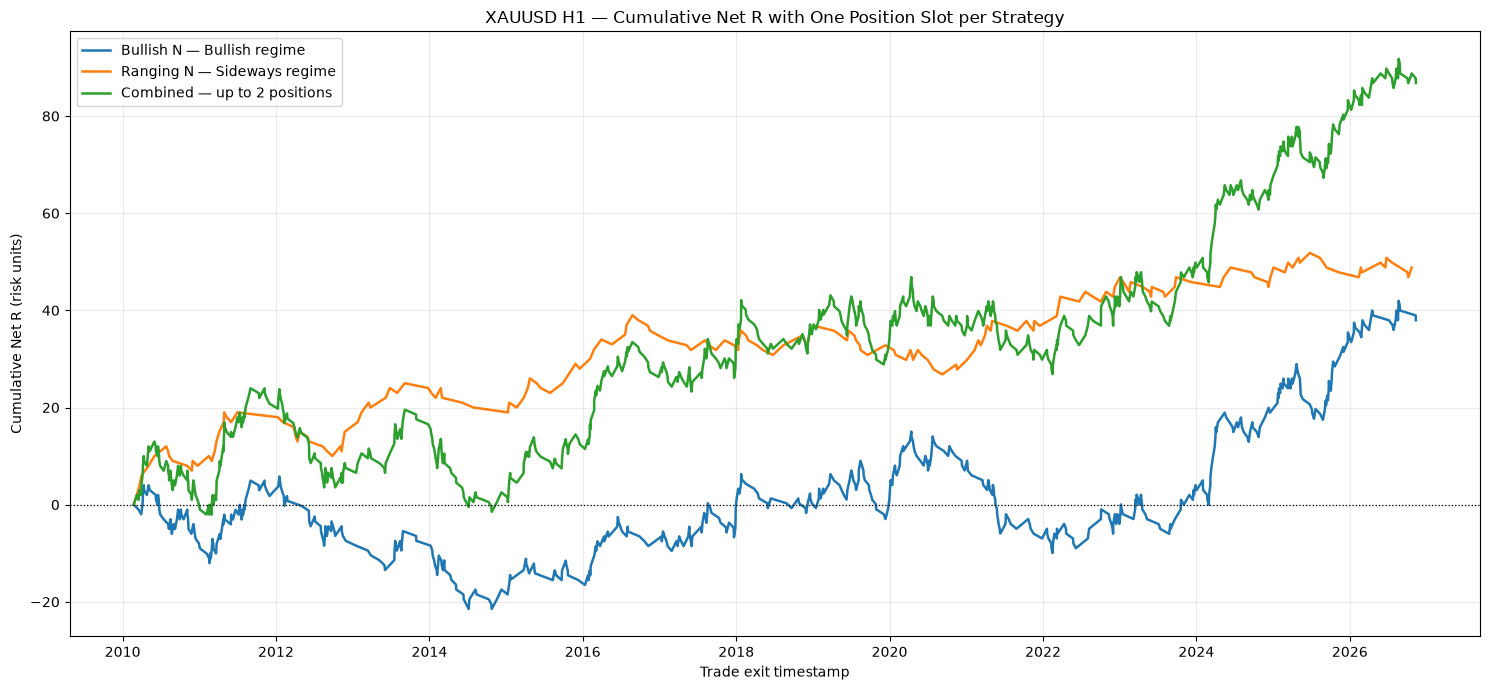

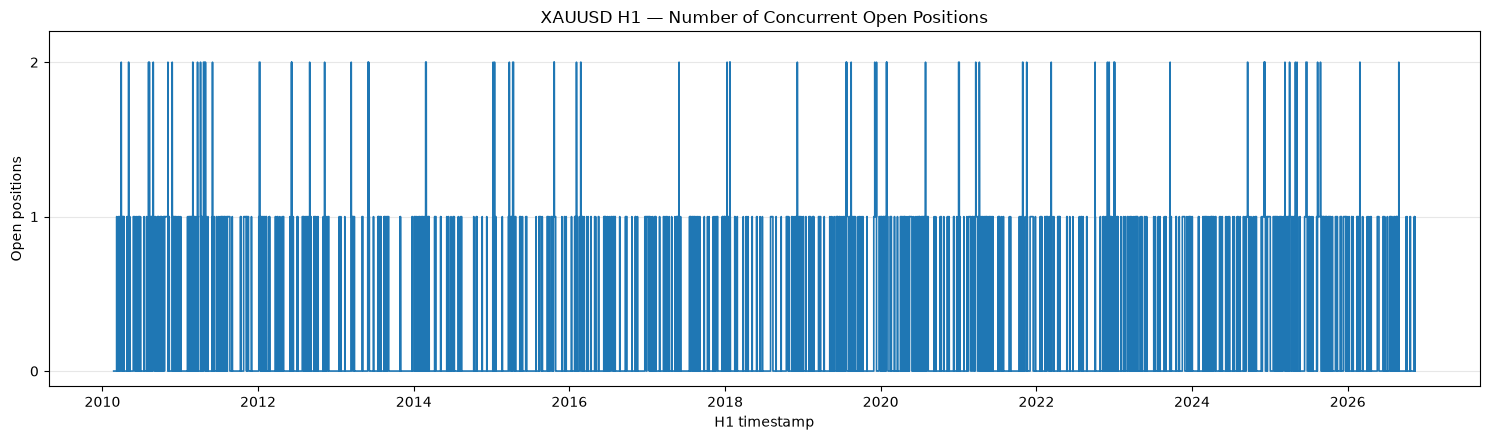

Saved charts:
/Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/assets/h1_one_position_per_strategy_cumulative_R.png
/Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/assets/h1_one_position_per_strategy_concurrency.png


In [10]:
# Cumulative R by strategy and combined.
def cumulative_r(frame: pd.DataFrame, start_time: pd.Timestamp) -> pd.Series:
    valid = frame[frame["result"].isin(VALID_RESULTS)].copy()
    if valid.empty:
        return pd.Series(dtype=float)
    increments = valid.groupby("exit_date")["R"].sum().sort_index()
    increments.loc[pd.Timestamp(start_time)] = increments.get(pd.Timestamp(start_time), 0.0)
    return increments.groupby(level=0).sum().sort_index().cumsum()

curve_series = {
    "Bullish N — Bullish regime": cumulative_r(strategy_trades["bullish"], data.index.min()),
    "Ranging N — Sideways regime": cumulative_r(strategy_trades["ranging"], data.index.min()),
    "Combined — up to 2 positions": cumulative_r(all_trades, data.index.min()),
}
plt.figure(figsize=(15, 7))
for label, curve in curve_series.items():
    if not curve.empty:
        plt.plot(curve.index, curve.values, linewidth=1.8, label=label)
plt.axhline(0, color="black", linewidth=0.9, linestyle=":")
plt.title("XAUUSD H1 — Cumulative Net R with One Position Slot per Strategy")
plt.xlabel("Trade exit timestamp")
plt.ylabel("Cumulative Net R (risk units)")
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
equity_chart_path = ASSET_DIR / "h1_one_position_per_strategy_cumulative_R.png"
plt.savefig(equity_chart_path, dpi=160, bbox_inches="tight")
plt.show()

plt.figure(figsize=(15, 4.5))
plt.step(data.index, active_portfolio, where="post", linewidth=1.2)
plt.yticks([0, 1, 2])
plt.ylim(-0.1, 2.2)
plt.title("XAUUSD H1 — Number of Concurrent Open Positions")
plt.xlabel("H1 timestamp")
plt.ylabel("Open positions")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
concurrency_chart_path = ASSET_DIR / "h1_one_position_per_strategy_concurrency.png"
plt.savefig(concurrency_chart_path, dpi=160, bbox_inches="tight")
plt.show()

print("Saved charts:")
print(equity_chart_path)
print(concurrency_chart_path)

## 10. Export reproducible results

The notebook exports trade-level records, summary statistics, the capacity audit, overlapping trade pairs, cumulative R, and the H1 concurrency time series.

In [11]:
# Add a human-readable strategy label for exports.
export_trades = valid_trades.copy()
export_trades["Strategy"] = export_trades["setup"].map({
    "bullish": "Bullish N — EMA/ADX Bullish",
    "ranging": "Ranging N — EMA/ADX Sideways",
})
export_trades.to_csv(OUTPUT_DIR / "XAUUSD_H1_one_position_per_strategy_trades.csv", index=False)
performance_summary.to_csv(OUTPUT_DIR / "XAUUSD_H1_one_position_per_strategy_performance.csv", index=False)
capacity_audit.to_csv(OUTPUT_DIR / "XAUUSD_H1_one_position_per_strategy_capacity_audit.csv", index=False)
legacy_comparison.to_csv(OUTPUT_DIR / "XAUUSD_H1_one_position_per_strategy_vs_notebook04.csv", index=False)
if not overlap_pairs_df.empty:
    overlap_pairs_df.to_csv(OUTPUT_DIR / "XAUUSD_H1_overlapping_bullish_ranging_trade_pairs.csv", index=False)

concurrency_timeseries = pd.DataFrame({
    "Timestamp": data.index,
    "Bullish N open positions": active_by_strategy["bullish"],
    "Ranging N open positions": active_by_strategy["ranging"],
    "Total open positions": active_portfolio,
})
concurrency_timeseries.to_csv(OUTPUT_DIR / "XAUUSD_H1_position_concurrency_timeseries.csv", index=False)

curve_table = pd.concat([
    curve.rename(label).rename_axis("exit_date")
    for label, curve in curve_series.items() if not curve.empty
], axis=1).sort_index().ffill().fillna(0.0)
curve_table.to_csv(OUTPUT_DIR / "XAUUSD_H1_one_position_per_strategy_cumulative_R.csv", index_label="exit_date")

print("Exported outputs:")
for filename in [
    "XAUUSD_H1_one_position_per_strategy_trades.csv",
    "XAUUSD_H1_one_position_per_strategy_performance.csv",
    "XAUUSD_H1_one_position_per_strategy_capacity_audit.csv",
    "XAUUSD_H1_one_position_per_strategy_vs_notebook04.csv",
    "XAUUSD_H1_overlapping_bullish_ranging_trade_pairs.csv",
    "XAUUSD_H1_position_concurrency_timeseries.csv",
    "XAUUSD_H1_one_position_per_strategy_cumulative_R.csv",
]:
    print(" -", OUTPUT_DIR / filename)

print("\nFinal result snapshot:")
display(performance_summary.round(3))
display(capacity_audit)

Exported outputs:
 - /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/outputs/XAUUSD_H1_one_position_per_strategy_trades.csv
 - /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/outputs/XAUUSD_H1_one_position_per_strategy_performance.csv
 - /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/outputs/XAUUSD_H1_one_position_per_strategy_capacity_audit.csv
 - /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/outputs/XAUUSD_H1_one_position_per_strategy_vs_notebook04.csv
 - /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/outputs/XAUUSD_H1_overlapping_bullish_ranging_trade_pairs.csv
 - /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/outputs/XAUUSD_H1_position_concurrency_timeseries.csv
 - /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/outputs/XAUUSD_H1_one_position_per_strategy_cumulative_R.csv

Final result snapshot:


/var/folders/wv/07prglm54x7ccrpg0dy54h_h0000gn/T/ipykernel_2113/1299962243.py:22: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  curve_table = pd.concat([


,Selection,Trades,Win rate %,Net R,Profit factor,Avg R,Max drawdown R,Ambiguous OCO
0,Bullish N + EMA/ADX Bullish,566,35.689,37.962,1.103,0.067,-27.254,0
1,Ranging N + EMA/ADX Sideways,194,41.753,48.818,1.431,0.252,-12.182,3
2,Combined — one slot per strategy,760,37.237,86.780,1.180,0.114,-25.431,3


,Metric,Value
0,Maximum simultaneous Bullish N positions,1
1,Maximum simultaneous Ranging N positions,1
2,Maximum combined open positions,2
3,H1 bars with both strategies open,777
4,H1 bars with at least one strategy open,19591
5,Overlapping Bullish/Ranging trade pairs,69


## 11. Interpretation and limitations

1. **The regime filter is applied before backtesting.** Only Bullish N setups signalled in a Bullish regime and Ranging N setups signalled in a Sideways regime enter their respective strategy queues.
2. **One position slot per strategy.** Bullish N and Ranging N each have an independent position lock. The combined stream can contain two concurrent positions, never more than one for either strategy.
3. **The previous Notebook 04 combined result already permitted cross-strategy overlap.** Notebook 04 backtested each strategy separately before concatenating the two trade streams. Notebook 05 makes the concurrency policy explicit and corrects the sequence of regime gating, so the performance difference versus Notebook 04 should not be attributed solely to concurrency.
4. **Pending-order simplification.** The capacity rule controls filled/open positions. Multiple unfilled candidate setups can exist in the setup stream; once a candidate fills, later signal setups in that strategy are skipped until the position exits. OCO orders within one Ranging N setup are mutually exclusive.
5. **Aggregate R is not account equity.** A combined +R curve assumes each trade risks one normalized R unit. It does not enforce total portfolio risk, capital allocation, margin, leverage, or dynamic position sizing.
6. **No transaction costs.** Spread, commission, swap, and slippage are excluded. They can materially affect H1 trading results.
7. **OHLC execution uncertainty.** SL is assumed to occur first when stop and target are both touched in one candle. Same-candle triggers on both OCO sides are marked ambiguous and excluded.
8. **Open trades at sample end.** `OPEN_AT_END` records are marked to the final candle close; they are not realized closed trades.
9. **Full-sample exploratory results.** This is not out-of-sample validation or forward testing. Historical results are not evidence of future profitability.

### Research conclusion

The notebook tests an operational interpretation of the selected policy: **maximum one open Bullish N position, maximum one open Ranging N position, and permission for both strategies to be open simultaneously.** The next step is to freeze these rules and validate them on new chronological data with realistic execution costs.